# Progetto 1: Segmentazione Clienti + Churn Prediction (Telco Customer Churn)
**Corso:** Laboratorio di Intelligenza Artificiale — A.A. 2025/2026  
**Autore:** Massimo Mantineo (Matricola: 541924)

## Introduzione, Agente Razionale (PEAS) e Obiettivi Formativi
Questo notebook implementa la pipeline completa sul dataset pubblico **IBM Telco Customer Churn** (`7.043` clienti), con l'obiettivo di prevedere l'abbandono dei clienti (*churn*) e comprenderne i profili comportamentali.

### Inquadramento Teorico: I 4 Approcci all'IA e il Modello PEAS
Nel settore delle telecomunicazioni acquisire un cliente nuovo costa molto più che trattenere un cliente attuale (**CAC** — *Customer Acquisition Cost*). Tra i **quattro approcci di Russell & Norvig** (*Pensare come umani*, *Agire come umani / Test di Turing*, *Pensare razionalmente con la logica* e **Agire Razionalmente**, Lezione 01), scegliamo l'**Agire Razionalmente**: distinguiamo **razionalità da onniscienza** (l'agente non prevede con certezza il futuro, ma sceglie l'azione più conveniente in condizioni di incertezza bilanciando clienti salvati e costo delle offerte).

- **Obiettivo (`P` — Performance):** ridurre gli abbandoni massimizzando il valore netto, cioè spendendo in azioni di retention meno del **CAC**.
- **Ambiente (`E` — Environment):** clientela Telco — **parzialmente osservabile** (non vediamo le offerte dei concorrenti), **stocastico/incerto** (lavoriamo con probabilità) e **dinamico/sequenziale** nelle campagne reali (mentre nell'esperimento batch sul dataset statico la singola previsione è fissa/episodica).
- **Azioni (`A` — Actuators):** offerte mirate, sconti dedicati e supporto tecnico prioritario.
- **Dati in ingresso (`S` — Sensors):** dati del gestionale clienti (**CRM**) su durata del contratto, bollette, piano tariffario e servizi attivi.

### Come Impara l'Agente (Mitchell T, E, P) e Perché Machine Learning
L'agente impara **offline** (*batch learning*, Lezione 03: addestrato una volta sull'intero blocco di dati storici, non cliente per cliente in tempo reale) attraverso due compiti:
1. **Apprendimento Supervisionato (Mitchell $\langle T, E, P \rangle$):** un algoritmo impara dall'**Esperienza (`E`)** di `5.634` clienti passati con esito noto se migliora sul **Compito (`T`)** di prevedere chi abbandonerà rispetto alla misura di **Prestazione (`P`)** (`Recall`, `Precision`, `F1-Score`, `AUC-ROC`).
2. **Apprendimento Non Supervisionato (Clustering K-Means + PCA):** dividere i clienti in gruppi simili senza mai guardare l'etichetta `Churn`, visualizzarli in 2D con la PCA e verificare se il gruppo aiuta le previsioni.

Con **30 caratteristiche** per cliente, regole scritte a mano risultano fragili, non si adattano al mercato e rispondono solo *sì* o *no*. I modelli di Machine Learning stimano invece una **probabilità continua da `0` a `1`**, consentendo di ordinare i clienti per rischio e scegliere da quale soglia intervenire.
- **Distinzione chiave (PEAS vs Mitchell):** nel **PEAS** la prestazione `P` misura il **guadagno economico reale** in azienda, mentre nel **Machine Learning (Mitchell)** misura **quanto prevede bene il modello** sui dati.

> **Rigore metodologico (Zero Data Leakage):** lo split stratificato 80/20 viene effettuato **prima** di qualsiasi calcolo parametrico (standardizzazione, One-Hot Encoding, K-Means e PCA), addestrando tutto esclusivamente sul Training Set.

## Setup e Configurazione Parametri
Raccogliamo in questa sezione gli import e gli iperparametri globali per garantire la completa riproducibilità degli esperimenti.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

# --- Configurazione Globale ---
IMAGES_DIR = "../relazione/images" if os.path.exists("../relazione") else "relazione/images"
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Parametri K-Means (valutazione per K in {2, 3, 4, 5, 6})
K_MIN = 2
K_MAX = 7
SELECTED_K = 3
KMEANS_N_INIT = 10

# Parametri MLP (Lezioni 07-08: regolarizzazione L2 esplicita + early stopping)
MLP_HIDDEN_LAYERS = (64, 32)
MLP_ALPHA = 0.1
MLP_MAX_ITER = 500

os.makedirs(IMAGES_DIR, exist_ok=True)

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
warnings.filterwarnings('ignore')

## 1. Caricamento dei Dati ed Esplorazione Iniziale
Carichiamo il dataset originale `Telco-Customer-Churn.csv` e ne ispezioniamo dimensioni, colonne e tipi di dato.

In [2]:
possible_data_paths = [
    "../data/Telco-Customer-Churn.csv",
    "data/Telco-Customer-Churn.csv",
]
DATA_PATH = next((p for p in possible_data_paths if os.path.exists(p)), possible_data_paths[0])

df = pd.read_csv(DATA_PATH)
print(f"Dimensioni del dataset: {df.shape[0]} righe, {df.shape[1]} colonne\n")
print("Tipi di dato:")
print(df.dtypes)
display(df.head())

Dimensioni del dataset: 7043 righe, 21 colonne

Tipi di dato:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Pulizia dei Dati
Dall'ispezione iniziale emergono tre interventi mirati di pulizia:
- **Rimozione di `customerID`:** è un codice identificativo unico per ogni riga che non contiene informazione generale sui comportamenti e non aiuta i modelli a generalizzare su clienti nuovi (restano **19 variabili** di ingresso e **1 target**).
- **Imputazione di `TotalCharges`:** importato come testo (`object`/`str`) per la presenza di **11 celle vuote (`" "`)**. Verifichiamo che tutte e 11 corrispondono esattamente a clienti appena arrivati (`tenure == 0`) che non hanno ancora pagato la prima bolletta: vengono quindi imputate coerentemente a `0.0 €` e convertite in `float64`.
- **Codifica del target `Churn`:** convertito da `Yes`/`No` a `1`/`0` (`1` = abbandono, `0` = cliente rimasto).

In [3]:
blank_rows = df[df['TotalCharges'].astype(str).str.strip() == ""]
print(f"Numero di righe con TotalCharges vuoto: {len(blank_rows)}")
print("Valori unici di tenure per queste righe:", blank_rows['tenure'].unique().tolist())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip().replace("", "0"))
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("\nTipi dopo la pulizia:")
print(df[['TotalCharges', 'Churn']].dtypes)
print(f"Valori nulli totali nel dataset: {df.isnull().sum().sum()}")

Numero di righe con TotalCharges vuoto: 11
Valori unici di tenure per queste righe: [0]

Tipi dopo la pulizia:
TotalCharges    float64
Churn             int64
dtype: object
Valori nulli totali nel dataset: 0


## 3. Analisi Esplorativa dei Dati (EDA): Sbilanciamento, Boxplot e Mediana
Prima di costruire qualsiasi modello analizziamo due aspetti fondamentali del dataset:

1. **Sbilanciamento delle classi (Lezione 04):** solo il **26,54%** dei clienti abbandona (`1.869` su `7.043`), mentre il **73,46%** resta. Di conseguenza l'**Accuracy** da sola inganna: un modello banale (*dummy classifier*) che risponde sempre *"resta"* otterrebbe comunque il `73,46%` di accuratezza ma **Recall 0%** (zero clienti in fuga intercettati).
2. **Cos'è, come si calcola e perché usiamo il Boxplot (Verde = Rimasti, Rosso = Abbandoni):**
   Il *Boxplot* permette di confrontare subito i due gruppi senza farsi falsare dai valori anomali (*outlier*):
   - **Linea nera centrale — Mediana:** si calcola **ordinando tutti i clienti dal valore più piccolo al più grande** e prendendo quello esattamente **nel mezzo** (se i clienti sono in numero pari, si fa la media dei due valori centrali). Così metà sta sotto e metà sta sopra senza farsi tirare su o giù dagli estremi.
   - **Scatola colorata (Quartili Q1–Q3):** va dal **25° al 75° percentile**, racchiudendo il **50% centrale** dei clienti (la sua lunghezza è lo scarto interquartile `IQR = Q3 - Q1`).
   - **Baffi e pallini:** i baffi si estendono fino a **1,5 volte** la lunghezza della scatola; i pallini oltre i baffi rappresentano i casi anomali (*outlier*).

**Primi segnali che emergono dai grafici:** chi abbandona resta molto meno (**mediana 10,0 mesi** contro **38,0 mesi** di chi resta) e paga bollette mensili più alte (**mediana 79,65 €** contro **64,43 €**). Il rischio è quindi fortemente concentrato sui clienti recenti ad alta spesa.

Tasso di churn complessivo nel dataset: 26.54% (1869 / 7043)

Mediane per classe (0 = Rimasti, 1 = Abbandoni):


,tenure,MonthlyCharges
Churn,,
0,38.0,64.43
1,10.0,79.65


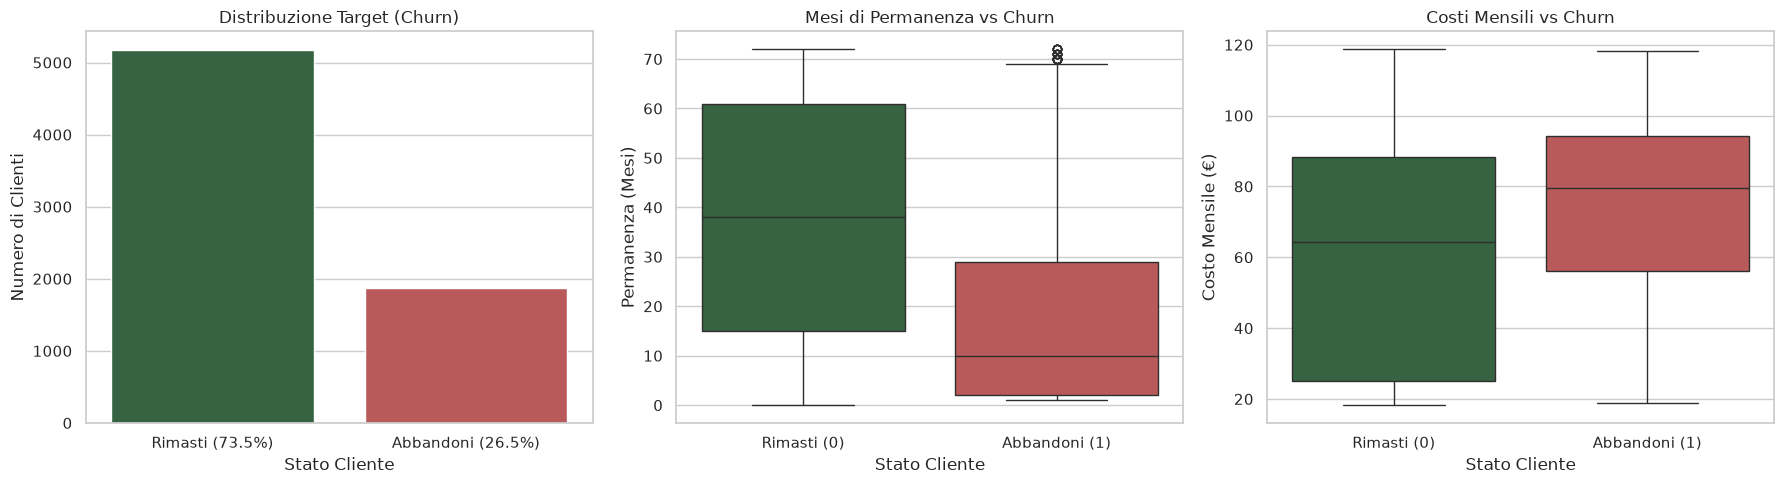

In [4]:
churn_rate = df['Churn'].mean()
med_stats = df.groupby('Churn')[['tenure', 'MonthlyCharges']].median()
print(f"Tasso di churn complessivo nel dataset: {churn_rate:.2%} ({df['Churn'].sum()} / {len(df)})")
print("\nMediane per classe (0 = Rimasti, 1 = Abbandoni):")
display(med_stats.round(2))

palette_churn = ['#2E6B3E', '#C94A4A']

# 1. Grafico a 3 pannelli per la relazione (distribuzione_churn.png)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(x='Churn', data=df, ax=axes[0], palette=palette_churn)
axes[0].set_title('Distribuzione Target (Churn)')
axes[0].set_xlabel('Stato Cliente')
axes[0].set_ylabel('Numero di Clienti')
axes[0].set_xticklabels(['Rimasti (73.5%)', 'Abbandoni (26.5%)'])

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1], palette=palette_churn)
axes[1].set_title('Mesi di Permanenza vs Churn')
axes[1].set_xlabel('Stato Cliente')
axes[1].set_ylabel('Permanenza (Mesi)')
axes[1].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2], palette=palette_churn)
axes[2].set_title('Costi Mensili vs Churn')
axes[2].set_xlabel('Stato Cliente')
axes[2].set_ylabel('Costo Mensile (€)')
axes[2].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Grafico boxplot a 2 pannelli per le slide (boxplot_permanenza_costi.png)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0], palette=palette_churn, width=0.55)
axes[0].set_title('Permanenza (Mesi)\n[Linea nera = Mediana]', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mesi di Abbonamento')
axes[0].set_xticklabels(['Rimasti', 'Abbandoni'], fontweight='bold')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1], palette=palette_churn, width=0.55)
axes[1].set_title('Costo Mensile (€)\n[Linea nera = Mediana]', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Spesa Mensile (€)')
axes[1].set_xticklabels(['Rimasti', 'Abbandoni'], fontweight='bold')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/boxplot_permanenza_costi.png', dpi=300, bbox_inches='tight')
plt.close(fig)

## 4. Split Stratificato e Preprocessing (Zero Data Leakage)
Per garantire un esperimento pulito ed evitare il **Data Leakage** (cioè far filtrare informazioni del Test Set durante l'addestramento falsando la valutazione finale), eseguiamo questi passaggi in ordine stretto:

1. **Split Stratificato 80/20 (fatto per primo):** dividiamo i `7.043` clienti in **80% Training Set** (`5.634` clienti per far studiare i modelli) e **20% Test Set** (`1.409` clienti tenuti completamente nascosti per l'esame finale). È **stratificato** perché mantiene la stessa esatta proporzione del **26,54%** di abbandoni sia nel training (`1.495` churn) sia nel test (`374` churn).
2. **Standardizzazione delle 3 variabili numeriche (`tenure`, `MonthlyCharges`, `TotalCharges`):**
   Le tre variabili hanno unità diversissime: i mesi arrivano a `72`, mentre la spesa totale supera `8.000 €`. Il computer non distingue mesi ed euro, quindi un numero grande schiaccerebbe uno piccolo nei calcoli di distanza o peso.
   - **Come si calcola (`StandardScaler`):** a ogni valore **togliamo la media e dividiamo per la deviazione standard** (che misura quanto i dati sono sparsi attorno alla media), calcolate **solo sul Training Set** (`fit_transform`) e poi applicate al Test Set (`transform`).
   - **Risultato:** portiamo tutto sullo **stesso metro di paragone**, dove **`0`** indica il cliente nella media, i valori **positivi** chi è sopra la media e i **negativi** chi è sotto la media (media `0`, deviazione standard `1`).
3. **One-Hot Encoding delle 16 variabili testuali (`3 + 27 = 30` variabili finali):**
   I modelli matematici leggono solo numeri, non parole come `"Fiber optic"` o `"DSL"`. Con `OneHotEncoder(drop='first')` trasformiamo le **16 variabili categoriali** in **27 colonne binarie `0/1`**. Per esempio, se il tipo di internet ha 3 casi (`Fibra`, `DSL`, `Nessuno`), bastano **2 colonne `0/1`** perché se sono entrambe `0` significa automaticamente il terzo caso: rimuovere una categoria ridondante per variabile evita la perfetta multicollinearità nei modelli lineari. Sommando `3` numeriche + `27` binarie otteniamo **30 feature finali**. *(Nota critica: nel K-Means con distanza euclidea `drop='first'` introduce una lieve asimmetria geometrica $1$ vs $\sqrt{2}$ rispetto alla categoria di riferimento, discussa nei limiti finali).*
4. **Doppia pipeline (`preprocessor_tree` senza standardizzazione per l'Albero CART):**
   Gli alberi decisionali guardano una caratteristica alla volta con soglie del tipo `<= s` e non risentono della scala (Lezione 05): addestrando l'albero senza standardizzazione leggiamo subito **mesi** ed **Euro (€)** reali.

In [5]:
X_raw = df.drop(columns=['Churn'])
y = df['Churn']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X_raw.columns if col not in num_cols]

# Pipeline con Standardizzazione (per K-Means, PCA, LogReg, MLP)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)
X_train_scaled = preprocessor_scaled.fit_transform(X_train_raw)
X_test_scaled = preprocessor_scaled.transform(X_test_raw)

cat_names = list(preprocessor_scaled.named_transformers_['cat'].get_feature_names_out(cat_cols))
feature_names = num_cols + cat_names

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_names, index=X_train_raw.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=feature_names, index=X_test_raw.index)

# Pipeline senza scaling (per Decision Tree CART interpretabile in unità originali)
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)
X_train_tree = preprocessor_tree.fit_transform(X_train_raw)
X_test_tree = preprocessor_tree.transform(X_test_raw)

X_train_tree_df = pd.DataFrame(X_train_tree, columns=feature_names, index=X_train_raw.index)
X_test_tree_df = pd.DataFrame(X_test_tree, columns=feature_names, index=X_test_raw.index)

print(f"Train Set: {X_train_scaled_df.shape} (Churn={y_train.mean():.2%})")
print(f"Test Set : {X_test_scaled_df.shape} (Churn={y_test.mean():.2%})")
display(X_train_scaled_df.head())

Train Set: (5634, 30) (Churn=26.54%)
Test Set : (1409, 30) (Churn=26.54%)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.262257,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.503635,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.749883,1.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.172722,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.989374,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 5. Apprendimento Non Supervisionato: Clustering K-Means
Sul solo Training Set standardizzato (`5.634` clienti, `30` feature) eseguiamo il **clustering**, cioè raggruppiamo i clienti simili **senza mai guardare l'etichetta `Churn`**.

### Come funziona K-Means passo passo (Lezione 06)
1. Sceglie $K$ centri iniziali (*centroidi*, con inizializzazione intelligente *k-means++*).
2. Assegna ogni cliente al centro più vicino in linea retta (distanza euclidea).
3. Ricalcola ogni centro come la **media** dei clienti finiti in quel gruppo.
4. Ripete i passi 2 e 3 finché i centri non si fermano (noi ripetiamo l'intera procedura da **10 partenze** diverse, `n_init=10`, tenendo la soluzione con inerzia minima).

### Perché scegliamo K-Means e non DBSCAN?
- **Profili medi chiari per il marketing:** ogni cluster è descritto dal proprio centroide medio.
- **Assegnazione pulita sui clienti nuovi (Zero Leakage):** K-Means impara i centri **solo sul Training Set** e poi assegna ogni cliente nuovo del Test Set al centro più vicino tramite `.predict()`, senza ricalcolare tutto da capo (cosa che DBSCAN non permette nativamente in `scikit-learn`).

### Come si calcolano e si leggono le due curve ($K \in \{2, 3, 4, 5, 6\}$)
- **Linea blu — Inerzia (WCSS, Metodo del Gomito):** per ogni cliente misura la distanza dal centro del proprio gruppo, la eleva al **quadrato** e **somma** tutto. Scende sempre all'aumentare di $K$, quindi cerchiamo il punto di piega (**gomito**).
- **Linea arancione — Silhouette Score ($s \in [-1, +1]$):** per ogni cliente confronta quanto è vicino ai compagni del **proprio gruppo** ($a$) rispetto al **gruppo vicino più prossimo** ($b$), calcolando $(b - a) / \max(a, b)$ (stimata su un campione riproducibile di `2.000` istanze di training, `random_state=42`). Più è vicina a `+1`, più i gruppi sono compatti dentro e ben separati fuori.

Tabella Valutazione Clustering (Training Set, 30 feature):


,K,Inerzia,Silhouette
0,2,33485.3863,0.2930
1,3,24642.3214,0.2817
2,4,22599.7888,0.2304
3,5,21178.5254,0.2093
4,6,19983.5212,0.1848


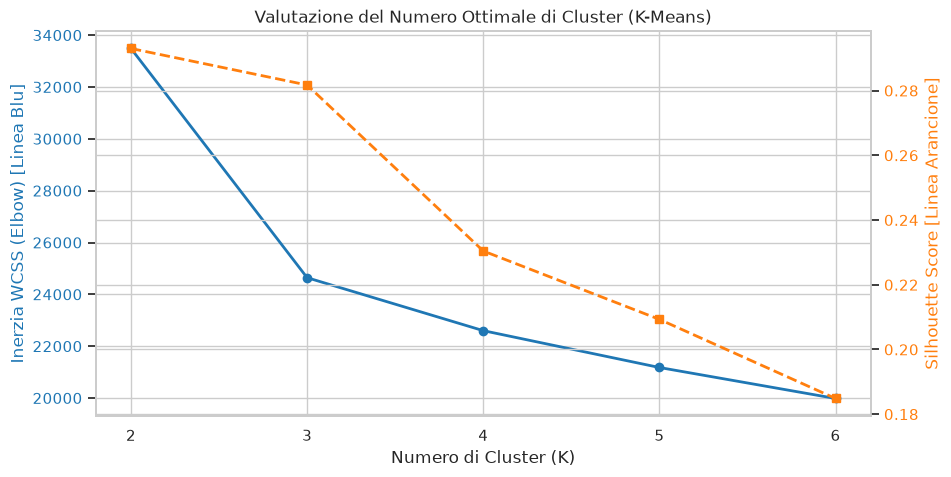

In [6]:
inertias = []
silhouettes = []
k_range = list(range(K_MIN, K_MAX))
cluster_results = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
    labels_k = km.fit_predict(X_train_scaled)
    sil = silhouette_score(X_train_scaled, labels_k, sample_size=2000, random_state=RANDOM_STATE)
    inertias.append(km.inertia_)
    silhouettes.append(sil)
    cluster_results.append({"K": k, "Inerzia": km.inertia_, "Silhouette": sil})

cluster_results_df = pd.DataFrame(cluster_results)
print("Tabella Valutazione Clustering (Training Set, 30 feature):")
display(cluster_results_df.round(4))

fig, ax1 = plt.subplots(figsize=(10, 5))
color_in = 'tab:blue'
ax1.set_xlabel('Numero di Cluster (K)')
ax1.set_ylabel('Inerzia WCSS (Elbow) [Linea Blu]', color=color_in)
ax1.plot(k_range, inertias, marker='o', color=color_in, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_in)
ax1.set_xticks(k_range)

ax2 = ax1.twinx()
color_sil = 'tab:orange'
ax2.set_ylabel('Silhouette Score [Linea Arancione]', color=color_sil)
ax2.plot(k_range, silhouettes, marker='s', color=color_sil, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_sil)

plt.title('Valutazione del Numero Ottimale di Cluster (K-Means)')
plt.savefig(f'{IMAGES_DIR}/clustering_scelta_k.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.1 Confronto di $K$, Scelta di $K=3$ e Verifica di Stabilità sul Test Set
Confrontando i candidati sul Training Set emergono tre comportamenti chiari:
- **$K = 2$ (troppo semplice):** ha la Silhouette leggermente più alta (`0.2930`), ma separa quasi solo chi ha internet da chi non lo ha, senza cogliere l'anzianità (`tenure`).
- **$K = 3$ (SCELTO):** coincide con il **gomito netto** dell'Inerzia (`33.485,39 -> 24.642,32`, mentre da $K=4$ la curva si appiattisce) mantenendo una buona compattezza (**Silhouette `0.2817`**, valore fisiologico in uno spazio a 30 dimensioni miste con molte variabili binarie).
- **$K \ge 4$ (frammentazione / *over-clustering*):** i gruppi si spezzettano troppo e la Silhouette crolla (`0.2304 -> 0.1848`).

Solo **dopo** aver formato i 3 gruppi ne osserviamo il tasso di abbandono e riordiniamo deterministicamente gli ID per rischio decrescente (`0: Volatili`, `1: Fedeli High-Value`, `2: Low-Cost`), proiettando poi i `1.409` clienti di test con `.predict()` per verificare che i segmenti siano stabili anche su dati mai visti.

Profilo Medio dei 3 Cluster (Training Set):


,Tenure Media,Costo Mensile (€),Costo Totale (€),Tasso Churn,Clienti
Cluster,,,,,
0,15.169,67.873,1005.532,0.434,2557
1,57.728,89.442,5145.229,0.159,1863
2,30.220,21.115,657.121,0.072,1214



Verifica Tasso di Churn per Cluster sul Test Set:


,mean,count
Cluster,,
0,0.433,677
1,0.133,420
2,0.080,312


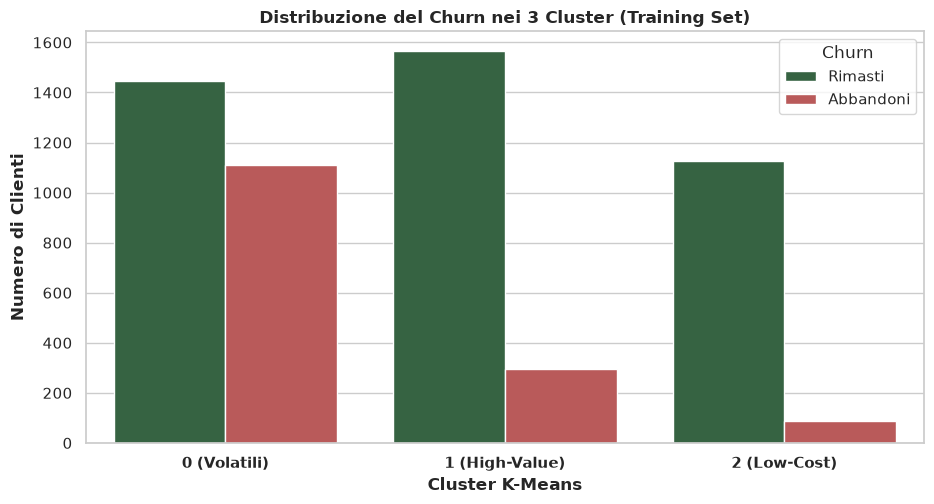

In [7]:
kmeans_chosen = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
raw_train_clusters = kmeans_chosen.fit_predict(X_train_scaled)
raw_test_clusters = kmeans_chosen.predict(X_test_scaled)

# Riordino deterministico degli ID per tasso di churn decrescente sul Training Set:
# Cluster 0 = Volatili (churn massimo), Cluster 1 = Fedeli High-Value, Cluster 2 = Low-Cost (churn minimo)
cluster_order = (
    pd.Series(y_train.values)
    .groupby(raw_train_clusters)
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
cluster_remap = {old_id: new_id for new_id, old_id in enumerate(cluster_order)}
train_clusters = np.array([cluster_remap[c] for c in raw_train_clusters])
test_clusters = np.array([cluster_remap[c] for c in raw_test_clusters])

df_train_clustered = X_train_raw.copy()
df_train_clustered['Churn'] = y_train
df_train_clustered['Cluster'] = train_clusters

cluster_profile = df_train_clustered.groupby('Cluster').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean',
    'TotalCharges': 'mean',
    'Churn': ['mean', 'count']
})
cluster_profile.columns = ['Tenure Media', 'Costo Mensile (€)', 'Costo Totale (€)', 'Tasso Churn', 'Clienti']
print("Profilo Medio dei 3 Cluster (Training Set):")
display(cluster_profile.round(3))

# Verifica coerenza sul Test Set (solo diagnostica)
df_test_clustered = X_test_raw.copy()
df_test_clustered['Churn'] = y_test
df_test_clustered['Cluster'] = test_clusters
print("\nVerifica Tasso di Churn per Cluster sul Test Set:")
display(df_test_clustered.groupby('Cluster')['Churn'].agg(['mean', 'count']).round(3))

# Grafico distribuzione Churn per Cluster
plt.figure(figsize=(9.5, 5.2))
ax = sns.countplot(x='Cluster', hue='Churn', data=df_train_clustered, palette=['#2E6B3E', '#C94A4A'])
plt.title('Distribuzione del Churn nei 3 Cluster (Training Set)', fontweight='bold')
plt.xlabel('Cluster K-Means', fontweight='bold')
plt.ylabel('Numero di Clienti', fontweight='bold')
ax.set_xticklabels(['0 (Volatili)', '1 (High-Value)', '2 (Low-Cost)'], fontweight='bold')
plt.legend(title='Churn', labels=['Rimasti', 'Abbandoni'], frameon=True)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn_cluster.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Visualizzazione 2D dei Cluster tramite PCA
**Cos'è e come funziona la PCA (Analisi delle Componenti Principali)?**  
Non possiamo disegnare **30 variabili** su uno schermo piatto in 2 dimensioni: la PCA riassume le feature standardizzate in **2 nuovi assi** scegliendo le direzioni lungo cui i clienti **variano di più** (massima varianza, Lezioni 05–06), conservando il **57,87%** dell'informazione totale:
- **PC1 (asse orizzontale, `39,37%` varianza):** è la direzione con la massima variabilità in assoluto, legata a **spesa mensile/totale e ampiezza dei servizi** (i clienti verdi *Low-Cost* senza internet si separano nettamente tutti a sinistra).
- **PC2 (asse verticale, `18,50%` varianza):** è la seconda direzione con più variabilità rimasta, **perpendicolare** (ortogonale e indipendente) alla prima, legata all'**anzianità contrattuale** (`tenure` e contratti biennali), separando i clienti blu *Volatili* (in basso) dai clienti arancioni *Fedeli High-Value* (in alto a destra).

> **Scelta metodologica:** la PCA viene usata **esclusivamente per disegnare il grafico 2D**; i modelli supervisionati usano invece tutte le 30 variabili originali per non perdere il restante `42,13%` di informazione.

Varianza spiegata: PC1 = 39.37%, PC2 = 18.50%, Totale = 57.87%

PC1 - Top pesi negativi: {'InternetService_No': -0.166, 'OnlineSecurity_No internet service': -0.166, 'OnlineBackup_No internet service': -0.166, 'DeviceProtection_No internet service': -0.166}
PC1 - Top pesi positivi: {'StreamingMovies_Yes': 0.173, 'tenure': 0.338, 'TotalCharges': 0.491, 'MonthlyCharges': 0.501}
PC2 - Top pesi negativi: {'MonthlyCharges': -0.277, 'PaymentMethod_Electronic check': -0.18, 'InternetService_Fiber optic': -0.163, 'PaperlessBilling_Yes': -0.11}
PC2 - Top pesi positivi: {'OnlineBackup_No internet service': 0.192, 'Contract_Two year': 0.221, 'TotalCharges': 0.338, 'tenure': 0.612}


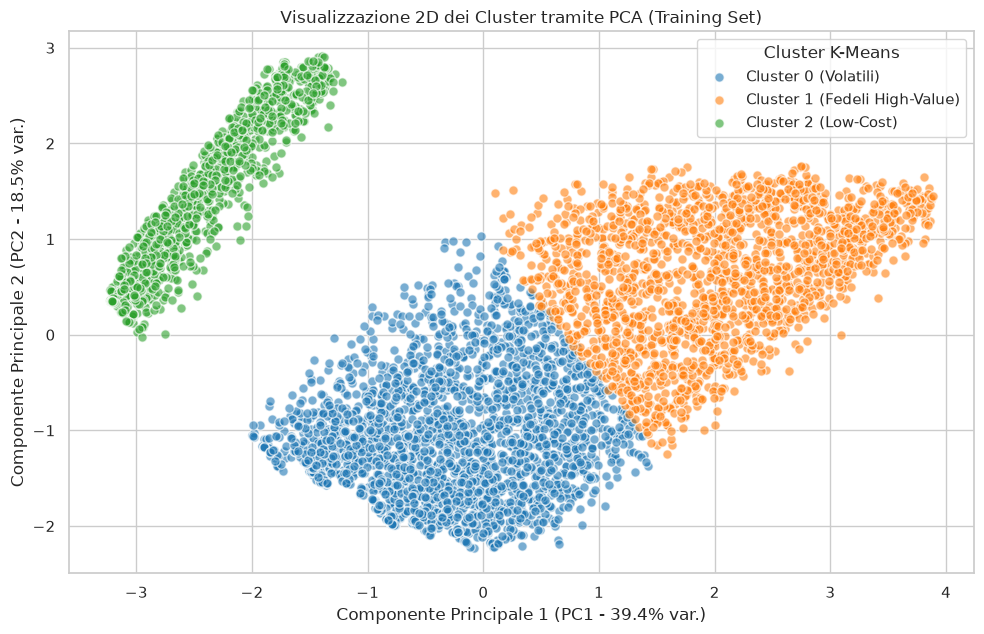

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)

var_ratio = pca.explained_variance_ratio_
print(f"Varianza spiegata: PC1 = {var_ratio[0]:.2%}, PC2 = {var_ratio[1]:.2%}, Totale = {var_ratio.sum():.2%}\n")

for i in range(2):
    loadings = pd.Series(pca.components_[i], index=feature_names).sort_values()
    print(f"PC{i+1} - Top pesi negativi:", loadings.head(4).round(3).to_dict())
    print(f"PC{i+1} - Top pesi positivi:", loadings.tail(4).round(3).to_dict())

plt.figure(figsize=(10, 6.5))
cluster_names = {
    0: 'Cluster 0 (Volatili)',
    1: 'Cluster 1 (Fedeli High-Value)',
    2: 'Cluster 2 (Low-Cost)'
}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for c in range(SELECTED_K):
    mask = train_clusters == c
    plt.scatter(
        X_train_pca[mask, 0], X_train_pca[mask, 1],
        label=cluster_names[c],
        color=colors[c],
        alpha=0.6,
        edgecolors='w',
        s=45
    )

plt.title('Visualizzazione 2D dei Cluster tramite PCA (Training Set)')
plt.xlabel(f'Componente Principale 1 (PC1 - {var_ratio[0]:.1%} var.)')
plt.ylabel(f'Componente Principale 2 (PC2 - {var_ratio[1]:.1%} var.)')
plt.legend(title="Cluster K-Means", frameon=True)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/clustering_visualizzazione_pca.png', dpi=300, bbox_inches='tight')
plt.show()

### Analisi Qualitativa dei 3 Tipi di Clienti Scoperti (Colori abbinati al grafico PCA)
- **Gruppo 0 — Volatili (Blu, `2.557` clienti train):** clienti recenti (**15,2 mesi**), spesa mensile media (**67,87 €**) e **tasso di abbandono critico del 43,4%** — confermato al **43,3%** sul Test Set (`677` clienti), prova concreta che la segmentazione è stabile su clienti nuovi. È la priorità assoluta per le azioni di retention.
- **Gruppo 1 — Fedeli High-Value (Arancione, `1.863` clienti train):** clienti storici (**57,7 mesi**), spesa alta (**89,44 €**) e **abbandoni contenuti al 15,9%** (`13,3%` sul Test Set). Costituiscono la base più consolidata e redditizia.
- **Gruppo 2 — Low-Cost (Verde, `1.214` clienti train):** permanenza intermedia (**30,2 mesi**), servizi telefonici base senza internet (**21,12 €/mese**) e **abbandoni minimi al 7,2%** (`8,0%` sul Test Set).

## 6. Apprendimento Supervisionato: Confronto tra i Tre Modelli
**Scopo del confronto:** capire quale modello prevede meglio sui `1.409` clienti nuovi del Test Set (senza data leakage) e verificare se aggiungere il gruppo K-Means porta un reale vantaggio predittivo.

Testiamo ogni modello su due configurazioni identiche (clonando il modello con `clone` e stesso `random_state=42`):
- **Dataset Base (`Orig`):** le **30 variabili** preprocessate.
- **Dataset Arricchito (`+Clust`):** **32 variabili**, aggiungendo due colonne `0/1` (`Cluster_1`, `Cluster_2`, con il Gruppo 0 *Volatili* come riferimento).

### Come Funzionano i 3 Modelli Valutati
1. **Regressione Logistica (Baseline Lineare):** ragiona come una pagella a punti — dà un **peso** a ogni dato del cliente (es. Fibra alza il rischio, tanti mesi lo abbassano), li somma e passa il totale dentro una curva a "S" chiamata **sigmoide** che schiaccia qualunque punteggio in una **probabilità da `0%` a `100%`**. Semplice, veloce, convessa e stabile: è il nostro punto di riferimento.
2. **Albero Decisionale CART (`max_depth=5`, White-Box):** funziona come una **catena di domande sì/no**. A ogni nodo prova tutte le possibili domande e sceglie quella che **abbassa di più l'indice di Gini**, creando due sottogruppi più puri. Limitiamo la profondità a `5` livelli per evitare che impari a memoria i singoli casi, e lo addestriamo **senza standardizzazione** così leggiamo subito **mesi ed Euro reali**.
3. **Rete Neurale MLP (`(64, 32)` neuroni):** lavora su **due livelli collegati**: un primo strato di `64` neuroni incrocia più indizi del cliente insieme e un secondo strato di `32` neuroni li raffina fino alla probabilità finale, cogliendo legami complessi. Usa **ReLU** (un interruttore che lascia passare solo i segnali positivi utili, evitando il blocco dell'apprendimento) e **Adam** (il meccanismo che a ogni errore aggiusta i pesi in modo rapido e intelligente). Contro l'**overfitting** — cioè imparare a memoria il training andando male sul test — applichiamo la **penalità L2** (`alpha=0.1`, tiene i pesi piccoli ed equilibrati) e l'**early stopping** (ferma lo studio appena il modello smette di migliorare su una piccola verifica interna).

In [9]:
ohe_cluster = OneHotEncoder(drop='first', sparse_output=False)
cl_train_dummies = pd.DataFrame(
    ohe_cluster.fit_transform(train_clusters.reshape(-1, 1)),
    columns=['Cluster_1', 'Cluster_2'],
    index=X_train_raw.index
)
cl_test_dummies = pd.DataFrame(
    ohe_cluster.transform(test_clusters.reshape(-1, 1)),
    columns=['Cluster_1', 'Cluster_2'],
    index=X_test_raw.index
)

X_train_scaled_clust = pd.concat([X_train_scaled_df, cl_train_dummies], axis=1)
X_test_scaled_clust = pd.concat([X_test_scaled_df, cl_test_dummies], axis=1)

X_train_tree_clust = pd.concat([X_train_tree_df, cl_train_dummies], axis=1)
X_test_tree_clust = pd.concat([X_test_tree_df, cl_test_dummies], axis=1)

model_specs = [
    (
        'Regressione Logistica (Baseline)',
        LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
        X_train_scaled_df, X_test_scaled_df,
        X_train_scaled_clust, X_test_scaled_clust
    ),
    (
        'Decision Tree (CART)',
        DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
        X_train_tree_df, X_test_tree_df,
        X_train_tree_clust, X_test_tree_clust
    ),
    (
        'MLP (Rete Neurale)',
        MLPClassifier(
            random_state=RANDOM_STATE,
            hidden_layer_sizes=MLP_HIDDEN_LAYERS,
            alpha=MLP_ALPHA,
            early_stopping=True,
            max_iter=MLP_MAX_ITER
        ),
        X_train_scaled_df, X_test_scaled_df,
        X_train_scaled_clust, X_test_scaled_clust
    ),
]

results = []
roc_data = {}
fitted_models = {}

for name, base_model, X_tr_o, X_te_o, X_tr_c, X_te_c in model_specs:
    m_orig = clone(base_model).fit(X_tr_o, y_train)
    y_pred_o = m_orig.predict(X_te_o)
    y_prob_o = m_orig.predict_proba(X_te_o)[:, 1]

    m_clust = clone(base_model).fit(X_tr_c, y_train)
    y_pred_c = m_clust.predict(X_te_c)
    y_prob_c = m_clust.predict_proba(X_te_c)[:, 1]

    fitted_models[name] = {
        'orig': m_orig, 'clust': m_clust,
        'y_pred_o': y_pred_o, 'y_pred_c': y_pred_c,
        'y_prob_o': y_prob_o, 'y_prob_c': y_prob_c,
    }

    results.append({
        'Modello': name,
        'Acc (Orig)': accuracy_score(y_test, y_pred_o),
        'Acc (Clust)': accuracy_score(y_test, y_pred_c),
        'Prec (Orig)': precision_score(y_test, y_pred_o),
        'Prec (Clust)': precision_score(y_test, y_pred_c),
        'Recall (Orig)': recall_score(y_test, y_pred_o),
        'Recall (Clust)': recall_score(y_test, y_pred_c),
        'F1 (Orig)': f1_score(y_test, y_pred_o),
        'F1 (Clust)': f1_score(y_test, y_pred_c),
        'AUC (Orig)': roc_auc_score(y_test, y_prob_o),
        'AUC (Clust)': roc_auc_score(y_test, y_prob_c),
    })

    fpr_o, tpr_o, _ = roc_curve(y_test, y_prob_o)
    fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_c)
    roc_data[name] = {
        'fpr_o': fpr_o, 'tpr_o': tpr_o, 'auc_o': roc_auc_score(y_test, y_prob_o),
        'fpr_c': fpr_c, 'tpr_c': tpr_c, 'auc_c': roc_auc_score(y_test, y_prob_c),
    }

results_df = pd.DataFrame(results)

## 7. Confronto delle Prestazioni sul Test Set e Come si Calcolano le Metriche
Valutiamo tutti i modelli sui `1.409` clienti di test mai visti (`1.035` rimasti e `374` abbandoni) alla soglia standard $\tau = 0.50$. Tutte le metriche nascono dai **4 conti della Matrice di Confusione** (`TP` = abbandoni beccati, `FN` = abbandoni persi, `FP` = falsi allarmi, `TN` = rimasti riconosciuti):
- **Accuracy:** risposte giuste diviso tutti i clienti $\rightarrow$ `(TP + TN) / (TP + TN + FP + FN)` *(inganna su dati sbilanciati)*.
- **Recall:** abbandoni beccati diviso tutti gli abbandoni veri $\rightarrow$ `TP / (TP + FN)` *(metrica chiave per proteggere il **CAC**)*.
- **Precision:** abbandoni beccati diviso tutti i clienti segnalati dal modello $\rightarrow$ `TP / (TP + FP)` *(misura quanto sono mirate le offerte)*.
- **F1-Score:** **media armonica** tra Precision e Recall $\rightarrow$ `2 × Precision × Recall / (Precision + Recall)` *(resta alta solo se entrambe sono buone)*.
- **AUC-ROC:** facendo scorrere la soglia da `0` a `1` si traccia la curva **Recall contro falsi allarmi (`FPR`)** e si calcola l'**area sotto la curva** (`0,5` = tirare a caso, `1,0` = separazione perfetta).

In [10]:
pd.options.display.float_format = '{:,.4f}'.format
print("Tabella Comparativa delle Performance sul Test Set:")
display(results_df)

print("\nMatrici di Confusione sul Test Set (Configurazione Base):")
for name in ['Regressione Logistica (Baseline)', 'Decision Tree (CART)', 'MLP (Rete Neurale)']:
    cm = confusion_matrix(y_test, fitted_models[name]['y_pred_o'])
    tn, fp, fn, tp = cm.ravel()
    print(f"- {name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Tabella Comparativa delle Performance sul Test Set:


,Modello,Acc (Orig),Acc (Clust),Prec (Orig),Prec (Clust),Recall (Orig),Recall (Clust),F1 (Orig),F1 (Clust),AUC (Orig),AUC (Clust)
0,Regressione Logistica (Baseline),0.8062,0.8034,0.6593,0.6540,0.5588,0.5508,0.6049,0.5980,0.8422,0.8420
1,Decision Tree (CART),0.7942,0.7942,0.6312,0.6312,0.5401,0.5401,0.5821,0.5821,0.8267,0.8267
2,MLP (Rete Neurale),0.7999,0.8034,0.6554,0.6655,0.5187,0.5214,0.5791,0.5847,0.8424,0.8429



Matrici di Confusione sul Test Set (Configurazione Base):
- Regressione Logistica (Baseline): TN=927, FP=108, FN=165, TP=209
- Decision Tree (CART): TN=917, FP=118, FN=172, TP=202
- MLP (Rete Neurale): TN=933, FP=102, FN=180, TP=194


### 7.1 Calibrazione della Soglia Decisionale, 5-Fold Cross-Validation e Pesi Bilanciati (Lezione 04)
Con la soglia standard $\tau = 0.50$, i classificatori su classi sbilanciate (`26,54%` churn) lasciano sfuggire circa il **44%** dei clienti in fuga (`FN = 165` sulla Logistica). Per proteggere l'azienda dal costo **CAC**, testiamo due strategie prive di data leakage:

- **Soglia calibrata ($\tau = 0.35$) verificata in 5-fold Cross-Validation sul solo Training Set:** dividiamo il solo Training Set in **5 fette uguali**; a turno **4 fette studiano** e **1 fetta verifica**, ripetendo 5 volte (`cross_val_predict`) senza mai toccare il Test Set. Sul Test Set la Recall sale dal **55,88% al 70,32%** (`TP` da `209` a `263`, `FN` scende da `165` a `111`, `F1` sale a `0.6138`).
- **Pesi bilanciati (`class_weight='balanced'`):** durante l'addestramento si dice al modello che **sbagliare un abbandono pesa circa 3 volte di più** che sbagliare un cliente che resta (in proporzione inversa al `26,5%` vs `73,5%`). La Recall sale al **78,34%** (`TP = 293`, `FN` ridotti a `81`, `F1 = 0.6136`).

In [11]:
# Calibrazione senza data leakage tramite out-of-fold probabilities sul Training Set
oof_probs = cross_val_predict(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    X_train_scaled_df, y_train, cv=5, method='predict_proba'
)[:, 1]
print(f"CV (5-fold su Training Set) con τ = 0.35 -> Recall: {recall_score(y_train, oof_probs >= 0.35):.4f}, Precision: {precision_score(y_train, oof_probs >= 0.35):.4f}, F1: {f1_score(y_train, oof_probs >= 0.35):.4f}\n")

# Valutazione sul Test Set delle configurazioni selezionate
test_probs_lr = fitted_models['Regressione Logistica (Baseline)']['y_prob_o']
lr_balanced = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced').fit(
    X_train_scaled_df, y_train
)

threshold_rows = []
for label, y_pred_eval in [
    ("LogReg (soglia standard τ = 0.50)", (test_probs_lr >= 0.50).astype(int)),
    ("LogReg (soglia calibrata τ = 0.35)", (test_probs_lr >= 0.35).astype(int)),
    ("LogReg (class_weight = 'balanced')", lr_balanced.predict(X_test_scaled_df)),
]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_eval).ravel()
    threshold_rows.append({
        "Configurazione": label,
        "Accuracy": accuracy_score(y_test, y_pred_eval),
        "Precision": precision_score(y_test, y_pred_eval),
        "Recall": recall_score(y_test, y_pred_eval),
        "F1-Score": f1_score(y_test, y_pred_eval),
        "TP (Intercettati)": tp,
        "FN (Persi)": fn,
        "FP (Falsi Allarmi)": fp,
    })

display(pd.DataFrame(threshold_rows))

CV (5-fold su Training Set) con τ = 0.35 -> Recall: 0.7043, Precision: 0.5649, F1: 0.6270



,Configurazione,Accuracy,Precision,Recall,F1-Score,TP (Intercettati),FN (Persi),FP (Falsi Allarmi)
0,LogReg (soglia standard τ = 0.50),0.8062,0.6593,0.5588,0.6049,209,165,108
1,LogReg (soglia calibrata τ = 0.35),0.7651,0.5445,0.7032,0.6138,263,111,220
2,LogReg (class_weight = 'balanced'),0.7381,0.5043,0.7834,0.6136,293,81,288


### 7.2 Curve ROC (Receiver Operating Characteristic)
La curva ROC confronta il **Tasso di Veri Positivi (`TPR` / Recall)** contro il **Tasso di Falsi Positivi (`FPR`)** al variare della soglia decisionale tra `0` e `1`. La diagonale tratteggiata rappresenta un classificatore casuale (`AUC = 0.50`): più la curva si spinge verso l'angolo in alto a sinistra, maggiore è la capacità discriminativa del modello.

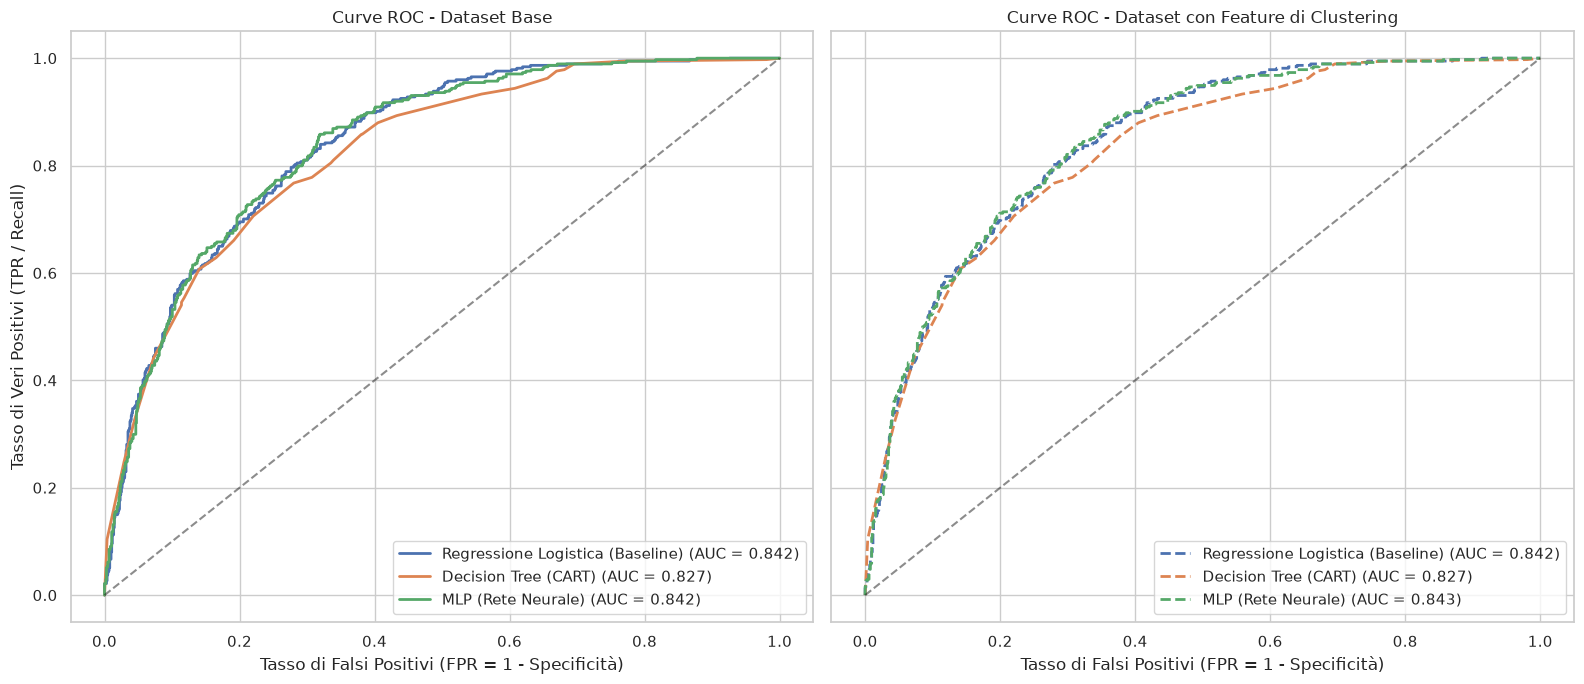

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for name, data in roc_data.items():
    axes[0].plot(data['fpr_o'], data['tpr_o'], label=f"{name} (AUC = {data['auc_o']:.3f})", linewidth=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('Tasso di Falsi Positivi (FPR = 1 - Specificità)')
axes[0].set_ylabel('Tasso di Veri Positivi (TPR / Recall)')
axes[0].set_title('Curve ROC - Dataset Base')
axes[0].legend(loc='lower right')

for name, data in roc_data.items():
    axes[1].plot(data['fpr_c'], data['tpr_c'], label=f"{name} (AUC = {data['auc_c']:.3f})", linestyle='--', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('Tasso di Falsi Positivi (FPR = 1 - Specificità)')
axes[1].set_title('Curve ROC - Dataset con Feature di Clustering')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/curve_roc.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.3 Confronto Visivo delle Prestazioni (Grafico a Barre)
Il grafico legge **direttamente i valori di `results_df`** (zero valori hardcoded) sui `1.409` clienti di test, confrontando **Blu = Dati Base (30 variabili)** e **Rosso = Dati con Gruppo K-Means (32 variabili)**:
- **Grafico 1 (Recall a soglia 50%):** la **Regressione Logistica Base** ottiene la Recall più alta (`55,9%`), mentre aggiungere il cluster la abbassa lievemente (`55,1%`), lascia identico il CART (`54,0%`) e fa salire leggermente la Rete Neurale (`51,9% -> 52,1%`).
- **Grafico 2 (AUC-ROC):** **Regressione Logistica (`0,842`)** e **Rete Neurale MLP (`0,842–0,843`)** hanno la stessa capacità discriminativa globale, superiore al singolo Albero CART (`0,827`). **A parità di risultato scegliamo il modello più semplice** (Regressione Logistica: meno parametri, più stabile e meno rischio di overfitting, Lezioni 03 e 06).

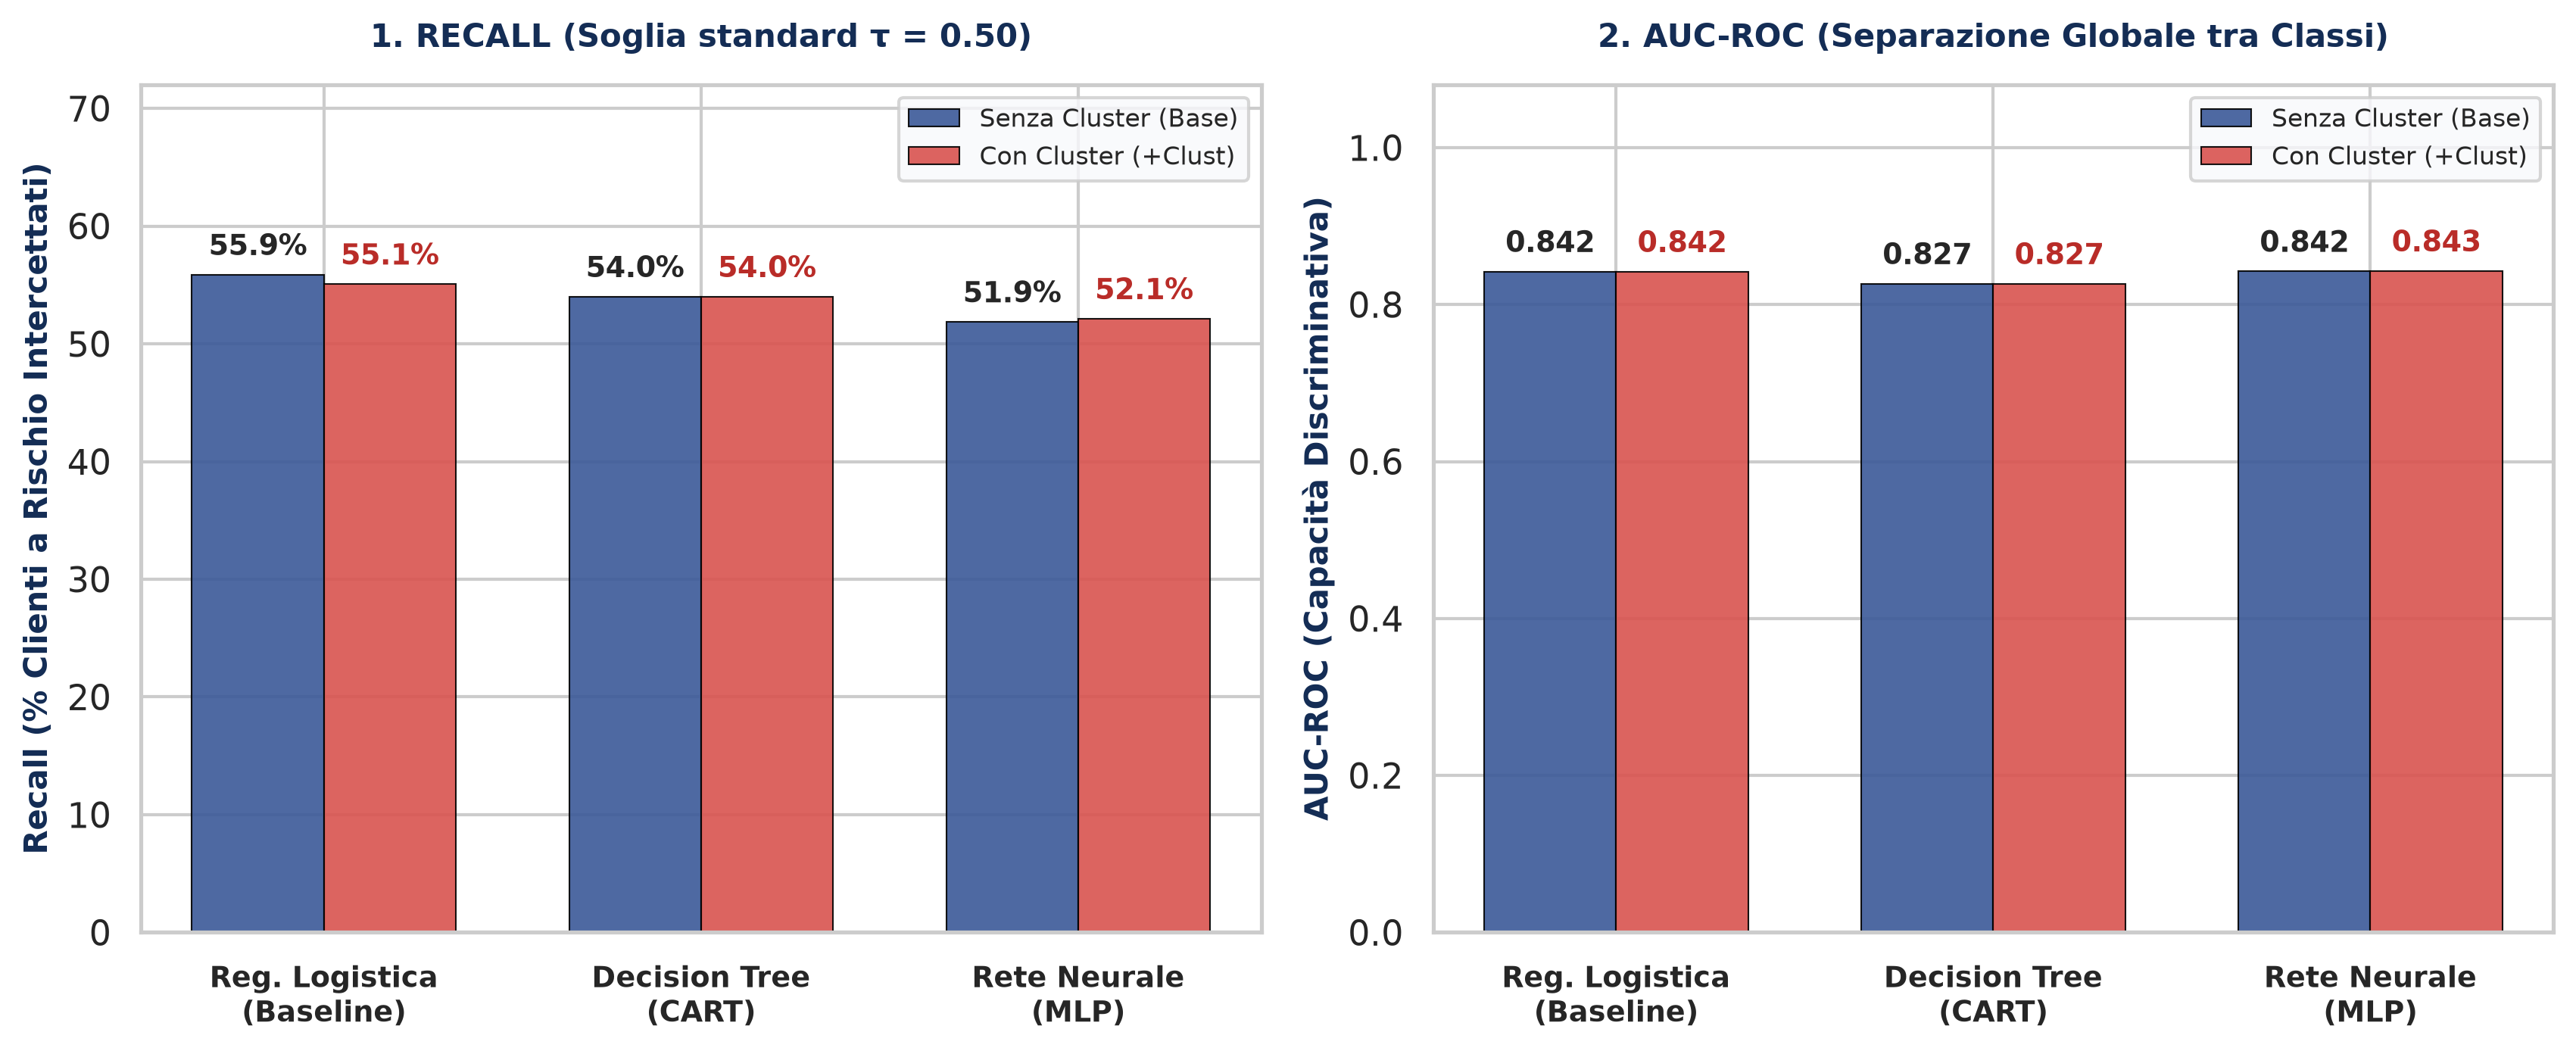

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=300)

labels_short = ['Reg. Logistica\n(Baseline)', 'Decision Tree\n(CART)', 'Rete Neurale\n(MLP)']
x = np.arange(len(labels_short))
width = 0.35

color_base = '#3B5998'
color_clust = '#D9534F'

recall_base = (results_df['Recall (Orig)'] * 100).tolist()
recall_clust = (results_df['Recall (Clust)'] * 100).tolist()
auc_base = results_df['AUC (Orig)'].tolist()
auc_clust = results_df['AUC (Clust)'].tolist()

# --- Subplot 1: RECALL ---
rects1 = ax1.bar(x - width/2, recall_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects2 = ax1.bar(x + width/2, recall_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax1.set_ylabel('Recall (% Clienti a Rischio Intercettati)', fontsize=10, fontweight='bold', color='#142D55')
ax1.set_title('1. RECALL (Soglia standard τ = 0.50)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(labels_short, fontsize=9, fontweight='bold')
ax1.set_ylim(0, 72)
ax1.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper right')

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B92C28')

# --- Subplot 2: AUC-ROC ---
rects3 = ax2.bar(x - width/2, auc_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects4 = ax2.bar(x + width/2, auc_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax2.set_ylabel('AUC-ROC (Capacità Discriminativa)', fontsize=10, fontweight='bold', color='#142D55')
ax2.set_title('2. AUC-ROC (Separazione Globale tra Classi)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(labels_short, fontsize=9, fontweight='bold')
ax2.set_ylim(0, 1.08)
ax2.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper right')

for rect in rects3:
    h = rect.get_height()
    ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects4:
    h = rect.get_height()
    ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B92C28')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/confronto_prestazioni_barre.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Analisi dell'Interpretabilità del Decision Tree (White-Box) e Indice di Gini
Visualizziamo i primi 3 livelli dell'albero CART addestrato sul Training Set **non standardizzato** (`5.634` clienti), così che ogni condizione si legga direttamente in **mesi** ed **Euro (€)**.

### Come leggere il grafico e come si calcola l'Indice di Gini ($K = 2$)
- **Colori:** riquadri **arancioni** = prevalenza di rimasti; riquadri **blu** = prevalenza di abbandoni.
- **Come si calcola l'Indice di Gini:** misura quanto un gruppo è misto; si prende la proporzione di rimasti e quella di abbandoni nel riquadro, si elevano entrambe al **quadrato**, si **sommano** e si sottrae il risultato da `1`:
  $$G_i = 1 - (\text{quota rimasti}^2 + \text{quota abbandoni}^2)$$
  Con **2 classi ($K = 2$)** varia quindi da **`0`** (gruppo puro al 100%, perché $1 - 1^2 - 0^2 = 0$, colore **scuro**) a **`0,5`** (metà e metà, perché $1 - 0.5^2 - 0.5^2 = 0.5$, colore **chiaro**).

### Il Percorso Critico a 3 Passi e l'Azione Aziendale
1. **Passo 1 (Livelli 1–2):** cliente recente (`tenure <= 16.5` mesi) + **Fibra Ottica** (`InternetService_Fiber optic > 0.5`) $\rightarrow$ abbandona già il **68,3%** (`593` su `868`).
2. **Passo 2 (Livello 3):** in più ha speso `TotalCharges <= 120.0 €` (primi 1–2 mesi) $\rightarrow$ riquadro blu scuro con **85,5% di abbandoni** (`165` su `193`, `Gini = 0.248`).
3. **Passo 3 (Livello 4 — split successivo nelle regole testuali):** senza supporto tecnico (`TechSupport_Yes <= 0.5`), il rischio sale all'**87,6%** (`162` su `185`, `Gini = 0.218`, contro il `37,5%` = `3/8` di chi ha supporto tecnico).

> **Azione aziendale immediata:** offrire supporto tecnico gratuito proattivo ai nuovi clienti in Fibra Ottica fin dai primi mesi.

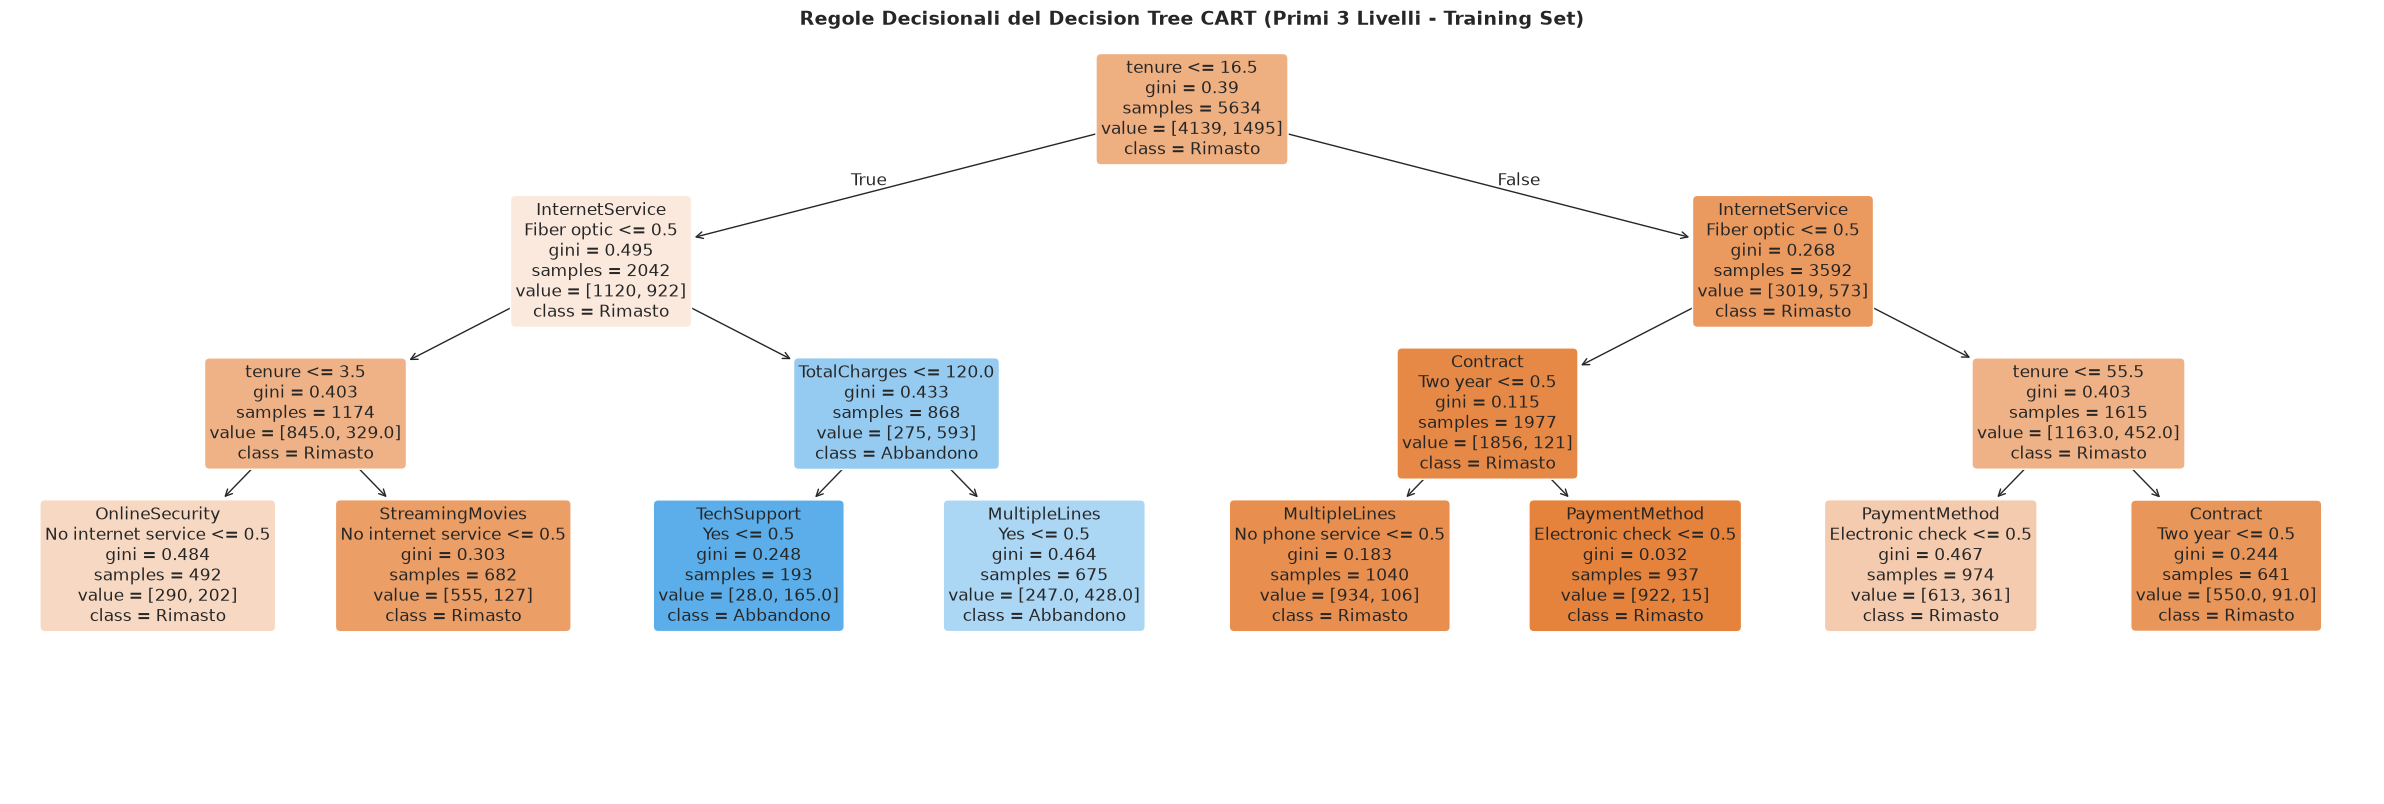

Regole testuali (primi 3 livelli):
|--- tenure <= 16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- tenure <= 3.50
|   |   |   |--- OnlineSecurity_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- OnlineSecurity_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tenure >  3.50
|   |   |   |--- StreamingMovies_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- StreamingMovies_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- TotalCharges <= 120.00
|   |   |   |--- TechSupport_Yes <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- TechSupport_Yes >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- TotalCharges >  120.00
|   |   |   |--- MultipleLines_Yes <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |---

In [14]:
dt_model_orig = fitted_models['Decision Tree (CART)']['orig']
tree_labels = [c.replace('_', '\n', 1) for c in X_train_tree_df.columns]

fig, ax = plt.subplots(figsize=(24, 8.2))
anns = plot_tree(
    dt_model_orig,
    max_depth=3,
    feature_names=tree_labels,
    class_names=['Rimasto', 'Abbandono'],
    filled=True,
    rounded=True,
    fontsize=12,
    ax=ax
)
# Rimuove i nodi segnaposto grigi '(...)' e relative frecce per guadagnare spazio e leggibilità
visible_y = []
for a in anns:
    if a.get_text().strip() == '(...)':
        a.set_visible(False)
        if getattr(a, 'arrow_patch', None) is not None:
            a.arrow_patch.set_visible(False)
    else:
        visible_y.append(a.xy[1])

if visible_y:
    y_min, y_max = min(visible_y), max(visible_y)
    pad = (y_max - y_min) * 0.16
    ax.set_ylim(y_min - pad, y_max + pad)

ax.set_title("Regole Decisionali del Decision Tree CART (Primi 3 Livelli - Training Set)", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/albero_decisionale.png', dpi=300, bbox_inches='tight')
plt.show()

print("Regole testuali (primi 3 livelli):")
print(export_text(dt_model_orig, feature_names=list(X_train_tree_df.columns), max_depth=3))


## 9. Discussione dei Risultati, Limiti, Sviluppi Futuri e Glossario di Sintesi

### 1. Cosa Portiamo a Casa (Risultati Chiave)
Ogni strumento ha un ruolo preciso: **K-Means** per capire i profili, **Regressione Logistica** per fare le previsioni, **Albero CART** per spiegare il *perché* e **soglia calibrata** per proteggere i costi.
- **Regole White-Box del Decision Tree:** permanenza breve (`tenure <= 16.5` mesi) + **Fibra Ottica** (`68,3%`) + primi 1–2 mesi (`TotalCharges <= 120.0 €`, **85,5%** su `165/193`) + assenza di **TechSupport** (**87,6%** al livello 4) indicano esattamente dove offrire supporto tecnico gratuito.
- **Ruolo Reale del Clustering:** aggiungere i cluster One-Hot produce un lieve calo sulla Regressione Logistica (`Recall: 55.88% -> 55.08%`) per ridondanza/collinearità con variabili già presenti, lascia invariato il CART (`Acc = 79.42%`, `Recall = 54.01%`) e porta solo un piccolo guadagno sull'MLP (`Acc: 79.99% -> 80.34%`, `F1: 0.5791 -> 0.5847`, `AUC: 0.8424 -> 0.8429`). Il valore principale di K-Means è quindi **descrittivo e strategico**: isola il segmento **Volatili** (`43.4%` churn sul train, `43.3%` sul test) rispetto a **Fedeli High-Value** (`15.9%`) e **Low-Cost** (`7.2%`).
- **Scelta del Modello più Semplice e Trade-off CAC:** con regolarizzazione L2 ed *early stopping* (Lezioni 07–08), l'MLP evita l'overfitting e raggiunge la Regressione Logistica (`AUC ~ 0.842–0.843`), ma **a parità di risultato scegliamo il modello più semplice** (Lezioni 03 e 06): la **Regressione Logistica** (`Acc 80.62%`, `Recall 55.88%`, `F1 0.6049`, pochissimi parametri, stabile e convessa). Calibrare la soglia a $\tau = 0.35$ (`Recall 70.32%`, `F1 0.6138`) o usare pesi bilanciati (`Recall 78.34%`, `F1 0.6136`) allinea infine l'agente razionale alla protezione dal CAC.

### 2. Limiti Metodologici ed Etici
- **Geometria di K-Means e One-Hot:** K-Means taglia lo spazio in gruppi **"a sfera"** (perché usa la distanza euclidea in linea retta dai centroidi, Lezione 06) e `drop='first'` introduce una lieve asimmetria di distanza ($1$ vs $\sqrt{2}$) rispetto alla categoria di riferimento.
- **Dati statici:** il dataset è una fotografia istantanea priva dello storico temporale dei reclami, delle chiamate al call center e dei guasti di linea.
- **Etica e affidabilità in produzione (Lezioni 01 e 05):** occorre garantire **privacy**, **trasparenza** sulle decisioni automatizzate e controlli di **fairness** per evitare discriminazioni legate ad attributi sensibili come età (`SeniorCitizen`) o genere (`gender`).

### 3. Sviluppi Futuri
- **Modelli *Ensemble*:** **Random Forest** (tanti alberi indipendenti in parallelo che votano a maggioranza, Lezione 05) e **XGBoost** (alberi costruiti uno dopo l'altro in sequenza dove ciascuno corregge gli errori del precedente).
- **Soft Clustering (Lezione 06):** usare le distanze continue di ogni cliente dai 3 centroidi K-Means invece della sola etichetta rigida di gruppo.
- **Curva Precision-Recall e Costi sul CAC (Lezione 04):** integrare l'analisi tramite **curva Precision-Recall** (più sensibile su classi sbilanciate) e ottimizzare una funzione di costo espressa direttamente in euro sul CAC reale.

---

### Mini-Glossario di Riferimento Rapido
- **4 Approcci IA / Mitchell:** Pensare/Agire come umani, Pensare/Agire razionalmente (scelto). Mitchell: impara da Esperienza (`E`) sul Compito (`T`) se migliora la Prestazione (`P`).
- **Split stratificato e Data Leakage:** divide `80%` training e `20%` test mantenendo lo stesso `26,54%` di abbandoni **prima** di ogni calcolo, così nessun dato del test entra nel training.
- **Standardizzazione:** a ogni numero si toglie la media e si divide per la deviazione standard (solo sul training): `0` = media, `+` sopra, `-` sotto.
- **One-Hot Encoding:** trasforma le `16` variabili testuali in `27` colonne `0/1` togliendo 1 categoria ridondante per variabile (es. 3 tipi $\rightarrow$ 2 colonne; `3 + 27 = 30`).
- **Boxplot e Mediana:** mediana = dati in ordine, valore centrale (o media dei 2 centrali se pari); scatola = `25°–75°` percentile (`50%` centrale); baffi = `1,5` volte la scatola; pallini = outlier.
- **K-Means, Inerzia e Silhouette:** K-Means assegna al centro più vicino e aggiorna i centri come media. Inerzia = somma distanze al quadrato dal centro. Silhouette (`-1` a `+1`) = `(distanza altro gruppo - distanza proprio gruppo) / massimo tra le due`.
- **PCA:** sceglie i 2 assi con massima varianza (`PC1 39,37%`, `PC2 18,50%` perpendicolare) per disegnare in 2D tenendo il `57,87%` dell'informazione.
- **Sigmoide, ReLU, Adam, L2, Early Stopping:** Sigmoide trasforma la somma in probabilità `0–1`; ReLU lascia passare solo segnali positivi; Adam aggiorna i pesi; L2 tiene i pesi equilibrati; Early Stopping ferma lo studio appena non migliora (anti-overfitting).
- **Metriche e AUC-ROC:** Recall = `TP/(TP+FN)`; Precision = `TP/(TP+FP)`; F1 = media armonica tra Precision e Recall; Accuracy = `(TP+TN)/tutti`; AUC-ROC = area sotto la curva Recall vs falsi allarmi (`0,5` caso – `1` perfetto).
- **5-fold Cross-Validation e Pesi Bilanciati:** 5-fold divide il training in 5 fette (4 studiano, 1 verifica a turno, mai il test); pesi bilanciati = sbagliare un abbandono pesa ~3 volte di più.
- **Indice di Gini:** $1 - (\text{quota rimasti}^2 + \text{quota abbandoni}^2)$; con 2 classi va da `0` (puro) a `0,5` (metà e metà).
- **Etica e Modelli Futuri:** Privacy, trasparenza e fairness (no discriminazioni su età/genere); Random Forest = alberi in parallelo a maggioranza; XGBoost = alberi in sequenza che correggono gli errori precedenti.